## Insurance Cost Prediction  

### IMPORTING THE libraries

In [2]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings as wr
wr.filterwarnings('ignore')

## reading the csv file 

In [4]:
df  = pd.read_csv('datasets_13720_18513_insurance(1).csv')

## basic checks 

In [5]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [7]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [8]:
df.shape 

(1338, 7)

In [9]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [10]:
print("duplicates:", df.duplicated().sum())
print(df["sex"].value_counts())
print(df["smoker"].value_counts())
print(df["region"].value_counts())

duplicates: 1
sex
male      676
female    662
Name: count, dtype: int64
smoker
no     1064
yes     274
Name: count, dtype: int64
region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64


In [11]:
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)

(1337, 7)


## spiliting the data 

In [73]:
x = df.drop(columns=["charges"])  
y = df["charges"]                  

In [74]:
num_cols = ["age", "bmi", "children"]
cat_cols = ["sex", "smoker", "region"]

In [75]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    df[num_cols + cat_cols], df["charges"], test_size=0.2, random_state=42
)

## EDA 

In [76]:
train = x_train.copy()
train["charges"] = y_train

### DATA CHECKS (full dataset, before the train/test split)
**Missing values:** none. Every column has 1338 non-null values.
**Duplicates:** 1 duplicate row found and removed before the split (1338 rows down to 1337), so the same record cannot appear in both train and test.
**Invalid values:** none. Age is 18 to 64, BMI 15.96 to 53.13, children 0 to 5, charges from 1,121 upward, all plausible.
**Category frequencies:**
- sex: male 676 (50.5%), female 662 (49.5%), balanced.
- smoker: no 1064 (79.5%), yes 274 (20.5%), imbalanced, about 4 to 1.
- region: southeast 364 (27.2%), southwest 325, northwest 325, northeast 324 (about 24% each), roughly balanced.
**Note:** all charts below use the training set only. Category counts in the charts are smaller than the totals above because they cover about 80% of the rows.

## Univariate 

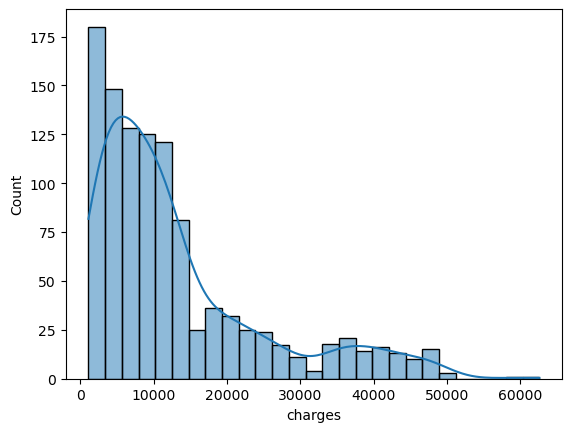

In [77]:
sns.histplot(train["charges"], kde=True)
plt.show()

**Charges (histogram)**
Charges are strongly right-skewed. Most people are billed under about 15,000, with the biggest group below 5,000, and a long tail reaches about 62,000. There is a second small bump around 35,000 to 48,000, which suggests a separate high-cost group (the smoker chart shows this is smokers). A skewed target means a log transform and error metrics like MAE or RMSE are worth considering.

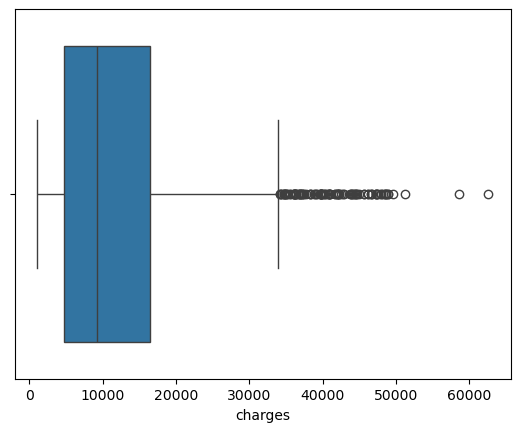

In [78]:
sns.boxplot(x=train["charges"])
plt.show()

**Charges (boxplot)**
The median charge is about 9,300, and the middle 50% of people are billed between about 4,700 and 16,500. The upper whisker stops at about 34,000, and above it there are dozens of outliers, stretching up to about 62,500, with two extreme points at about 58,500 and 62,500. There are no low outliers, so the skew is entirely on the high side. Earlier checks show these high bills are mostly smokers, so they are genuine high-cost cases, not data errors. They are therefore kept and capped with winsorization at the 1st and 99th percentiles, not removed. Of the 1,069 training rows, 106 (9.9%) lie above the IQR upper limit of 34,007, and 103 of them (97%) are smokers, so they are genuine high-cost cases and not data errors. They are kept, not removed or capped, and tree-based models are not sensitive to such values.

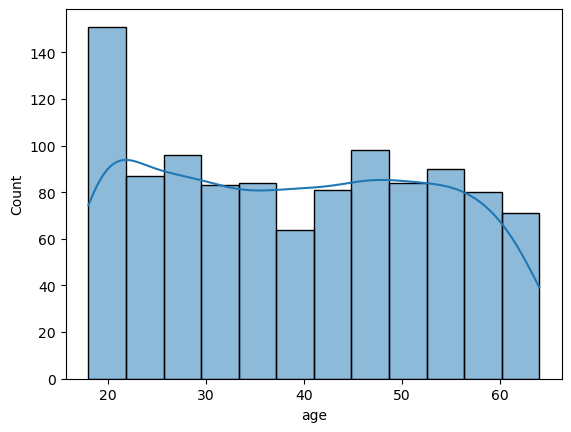

In [79]:
sns.histplot(train["age"], kde=True)
plt.show()

**Age (histogram)**
Ages are spread fairly evenly from 18 to 64, with no skew. The one clear spike is at 18 to 22 (about 150 people), so young adults are slightly over-represented. No unusual values.

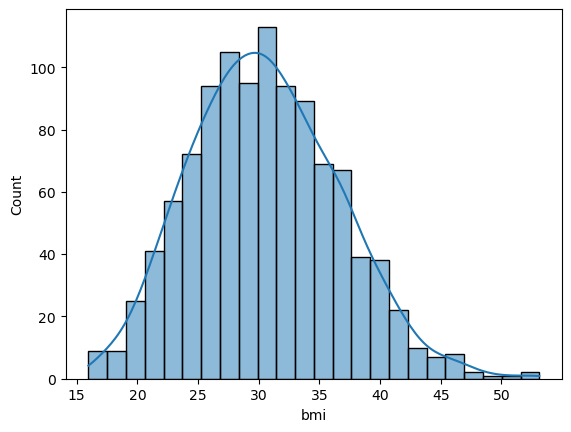

In [80]:
sns.histplot(train["bmi"], kde=True)
plt.show()

**BMI (histogram)**
BMI is roughly bell-shaped and centred near 30, with a slight right tail up to about 53. The typical person in this data is at the overweight/obese boundary (30).

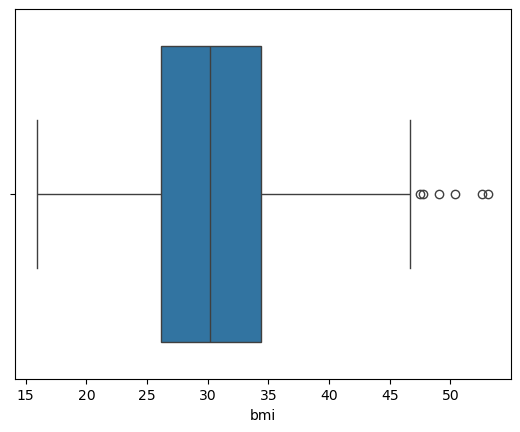

In [81]:
sns.boxplot(x=train["bmi"])
plt.show()

**BMI (boxplot)**
The median is about 30, with the middle half of values between about 26 and 34.5. Only high outliers appear (about 6 values above 47, up to about 53), and none are low.  This matters because smoking is the strongest cost driver.

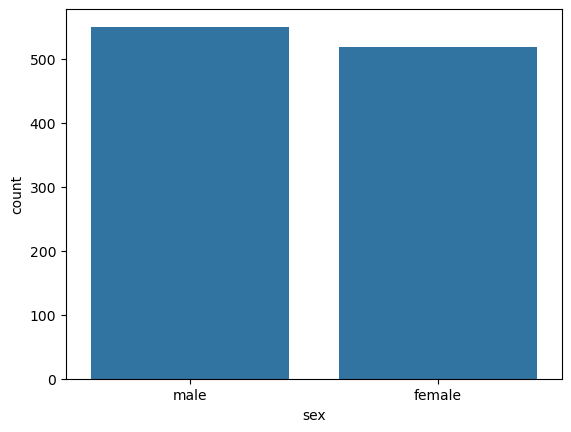

In [82]:
sns.countplot(x="sex", data=train)
plt.show()


**Sex (countplot)**
Male (about 550) and female (about 520) are almost equally represented, so no balance problem.

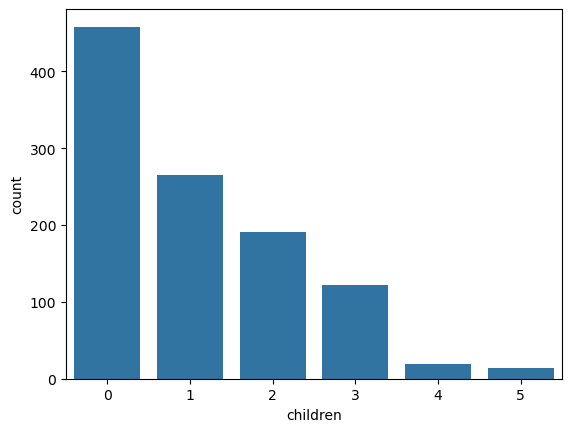

In [83]:
sns.countplot(x="children", data=train)
plt.show()

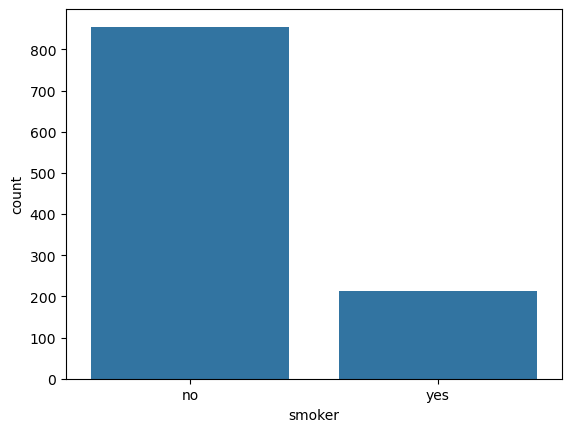

In [84]:
sns.countplot(x="smoker", data=train)
plt.show()

**Smoker (countplot)**
Non-smokers outnumber smokers by about 4 to 1 (roughly 855 against 215), so smokers are a minority group. This matters because smoking is the strongest cost driver, which is why the train/test split is stratif on smoker.


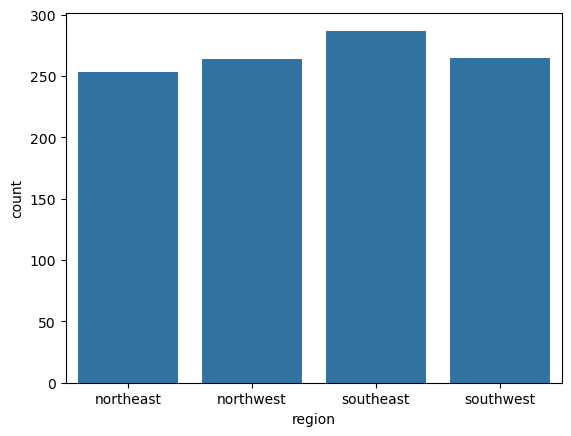

In [85]:
sns.countplot(x="region", data=train)
plt.show()


**Region (countplot)**
All four regions have about 250 to 290 people. Southeast is slightly the largest. No rare category here.

## Bivariate 

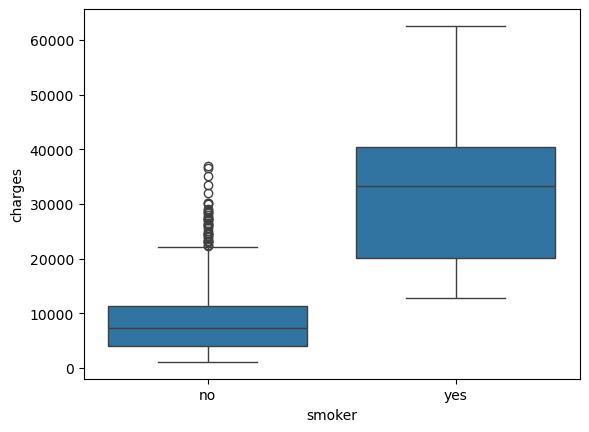

In [86]:
sns.boxplot(x="smoker", y="charges", data=train)
plt.show()

**Smoker vs charges (boxplot)**
This is the clearest pattern in the data. The non-smoker median is about 7,500, while the smoker median is about 33,000, and the two boxes barely overlap. Non-smokers have many high outliers (about 22,000 to 37,000), but even those sit below the typical smoker bill.

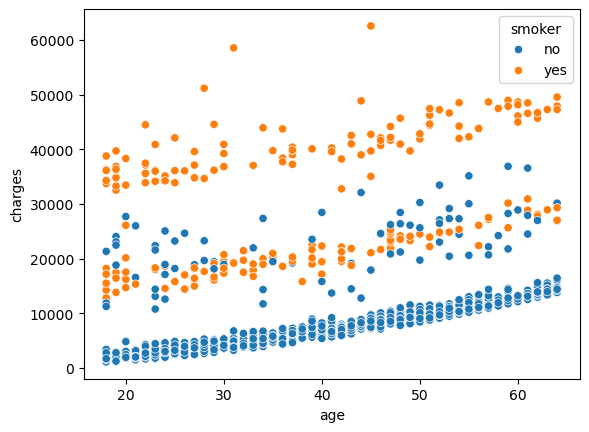

In [87]:
sns.scatterplot(x="age", y="charges", hue="smoker", data=train)
plt.show()

**Age vs charges, coloured by smoker (scatter)**
Charges rise steadily with age for everyone. The points form three bands: non-smokers along the bottom (about 2,000 at 18 up to about 15,000 at 64), a middle band of about 15,000 to 30,000 that mixes both groups, and a top band of about 33,000 to 50,000 that is almost all smokers. Smokers pay more at every age.

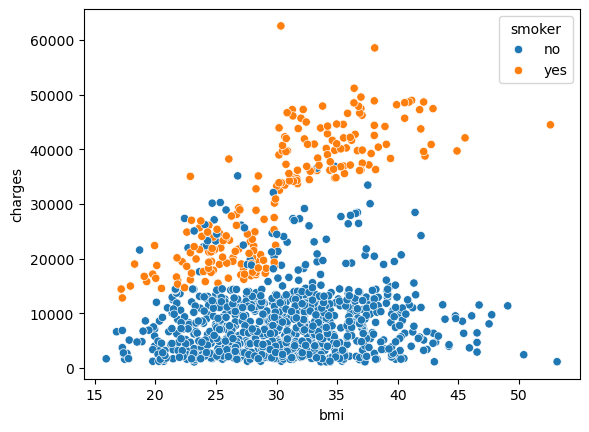

In [88]:
sns.scatterplot(x="bmi", y="charges", hue="smoker", data=train)
plt.show()


**BMI vs charges, coloured by smoker (scatter)**
For non-smokers, charges stay mostly under about 15,000 whatever the BMI, so BMI has little effect for them. For smokers, charges jump from about 15,000 to 25,000 when BMI is below 30 to about 35,000 to 50,000 when BMI is above 30. So BMI matters mainly in combination with smoking, an interaction a plain linear model cannot capture without help.

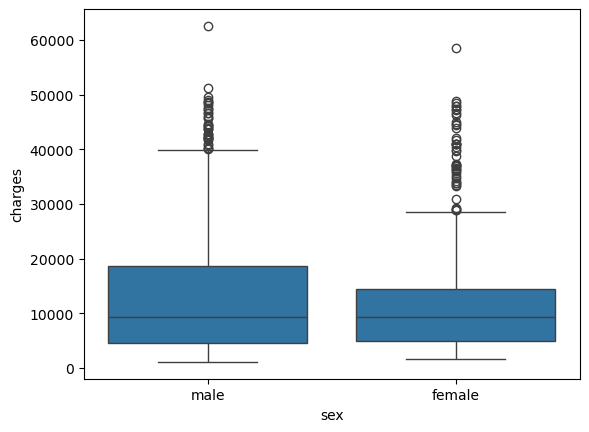

In [89]:
sns.boxplot(x="sex", y="charges", data=train)
plt.show()

**Sex vs charges (boxplot)**
The medians are nearly identical (about 9,300). Males have a wider spread and a higher upper whisker (about 40,000 against about 28,000), but both groups have many high outliers. Sex alone separates charges very little.

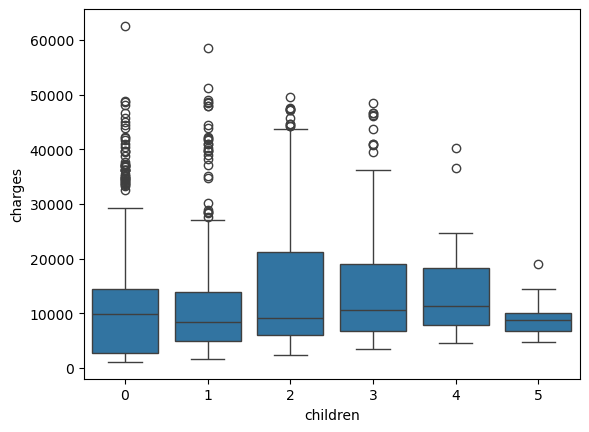

In [90]:
sns.boxplot(x="children", y="charges", data=train)
plt.show()

 **Children vs charges (boxplot)**
The medians are similar for 0 to 4 children (about 9,000 to 11,000) with no clear trend. The 5-children group is very small (about 14 people), so its narrower, lower box is not reliable. Children look like a weak predictor on their own.

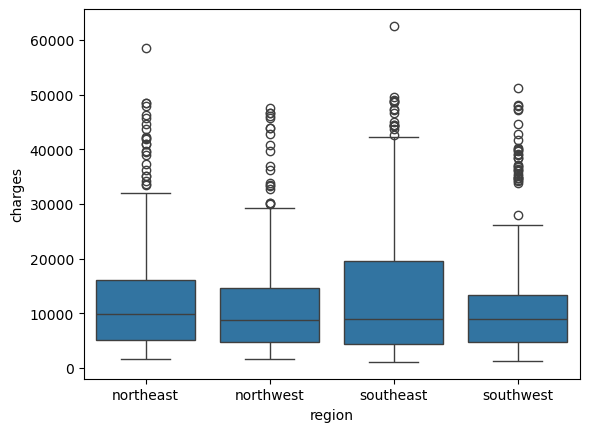

In [91]:
sns.boxplot(x="region", y="charges", data=train)
plt.show()

**Region vs charges (boxplot)**
Medians are similar across all four regions (about 9,000 to 10,000). Southeast has the widest spread and the highest outlier (about 62,000), but outliers appear in every region. Region looks like a weak predictor on its own.

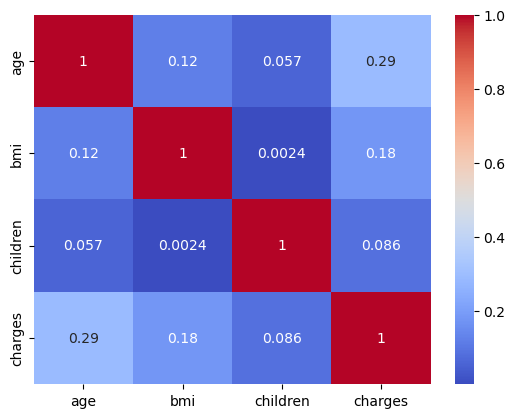

In [92]:
sns.heatmap(train[["age", "bmi", "children", "charges"]].corr(), annot=True, cmap="coolwarm")
plt.show()


**Correlation heatmap (numeric columns only)**
Age has the strongest correlation with charges (0.29), then BMI (0.18) and children (0.09). Features are almost uncorrelated with each other (the largest is age and BMI at 0.12), so there is no redundancy problem. This heatmap covers only age, BMI and children. It excludes smoker, sex and region, so it understates the importance of smoking and should not be read as a feature-importance ranking.

In [93]:
def iqr_limits(s):
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

In [94]:
bmi_low, bmi_high = iqr_limits(x_train["bmi"])
ch_low, ch_high = iqr_limits(y_train)
print("bmi limits:", round(bmi_low, 2), round(bmi_high, 2))
print("charges limits:", round(ch_low), round(ch_high))


bmi limits: 13.8 46.8
charges limits: -12809 34007


In [95]:
print("charges outliers:", (y_train > ch_high).sum(), "of", len(y_train))
print(x_train.loc[y_train > ch_high, "smoker"].value_counts())
print("bmi outliers:", ((x_train["bmi"] < bmi_low) | (x_train["bmi"] > bmi_high)).sum())


charges outliers: 106 of 1069
smoker
yes    103
no       3
Name: count, dtype: int64
bmi outliers: 6


## encoding 

In [105]:
x_train_enc = pd.get_dummies(x_train, drop_first=True, dtype=int)
x_test_enc = pd.get_dummies(x_test, drop_first=True, dtype=int)

In [106]:
print(x_train_enc.columns.tolist())
print(list(x_train_enc.columns) == list(x_test_enc.columns))

['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']
True


## models 

In [107]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

lr = LinearRegression()
dt = DecisionTreeRegressor(max_depth=4, random_state=42)
rf = RandomForestRegressor(random_state=42)
gb = GradientBoostingRegressor(random_state=42)

In [108]:
lr.fit(x_train_enc, y_train)

LinearRegression()

In [109]:
dt.fit(x_train_enc, y_train)

DecisionTreeRegressor(max_depth=4, random_state=42)

In [110]:
rf.fit(x_train_enc, y_train)

RandomForestRegressor(random_state=42)

In [111]:
gb.fit(x_train_enc, y_train)

GradientBoostingRegressor(random_state=42)

In [112]:
print("Linear Regression:", round(lr.score(x_train_enc, y_train), 3))
print("Decision Tree:", round(dt.score(x_train_enc, y_train), 3))
print("Random Forest:", round(rf.score(x_train_enc, y_train), 3))
print("Gradient Boosting:", round(gb.score(x_train_enc, y_train), 3))

Linear Regression: 0.73
Decision Tree: 0.855
Random Forest: 0.974
Gradient Boosting: 0.892


## metrices 

In [113]:
from sklearn.model_selection import cross_val_score


def compare(name, model):
    r2 = cross_val_score(model, x_train_enc, y_train, cv=5, scoring="r2")
    mae = -cross_val_score(model, x_train_enc, y_train, cv=5, scoring="neg_mean_absolute_error")
    rmse = -cross_val_score(model, x_train_enc, y_train, cv=5, scoring="neg_root_mean_squared_error")
    print(name, "| R2:", round(r2.mean(), 3), "(+/-", round(r2.std(), 3), ") | MAE:", round(mae.mean()), "| RMSE:", round(rmse.mean()))


In [114]:
compare("Linear Regression", lr)
compare("Decision Tree", dt)
compare("Random Forest", rf)
compare("Gradient Boosting", gb)

Linear Regression | R2: 0.726 (+/- 0.025 ) | MAE: 4207 | RMSE: 6114
Decision Tree | R2: 0.833 (+/- 0.022 ) | MAE: 2736 | RMSE: 4771


Random Forest | R2: 0.82 (+/- 0.008 ) | MAE: 2790 | RMSE: 4956
Gradient Boosting | R2: 0.834 (+/- 0.016 ) | MAE: 2646 | RMSE: 4757


## hyperparameter tuning 

In [115]:
from sklearn.model_selection import GridSearchCV

gb_grid = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    {"n_estimators": [50, 100, 200],
     "max_depth": [2, 3, 4],
     "learning_rate": [0.05, 0.1]},
    cv=5, scoring="r2")
gb_grid.fit(x_train_enc, y_train)

print(gb_grid.best_params_)
print(round(gb_grid.best_score_, 3))

{'learning_rate': 0.05, 'max_depth': 2, 'n_estimators': 200}
0.843


In [116]:
dt_grid = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    {"max_depth": [3, 4, 5, 6],
     "min_samples_leaf": [5, 10, 20]},
    cv=5, scoring="r2")
dt_grid.fit(x_train_enc, y_train)

print(dt_grid.best_params_)
print(round(dt_grid.best_score_, 3))

{'max_depth': 4, 'min_samples_leaf': 5}
0.834


In [117]:
compare("Gradient Boosting (tuned)", gb_grid.best_estimator_)
compare("Decision Tree (tuned)", dt_grid.best_estimator_)

Gradient Boosting (tuned) | R2: 0.843 (+/- 0.022 ) | MAE: 2613 | RMSE: 4625
Decision Tree (tuned) | R2: 0.834 (+/- 0.022 ) | MAE: 2705 | RMSE: 4760


In [118]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

final_model = gb_grid.best_estimator_
pred = final_model.predict(x_test_enc)

print("Test R2:", round(r2_score(y_test, pred), 3))
print("Test MAE:", round(mean_absolute_error(y_test, pred)))
print("Test RMSE:", round(mean_squared_error(y_test, pred) ** 0.5))

Test R2: 0.899
Test MAE: 2523
Test RMSE: 4299


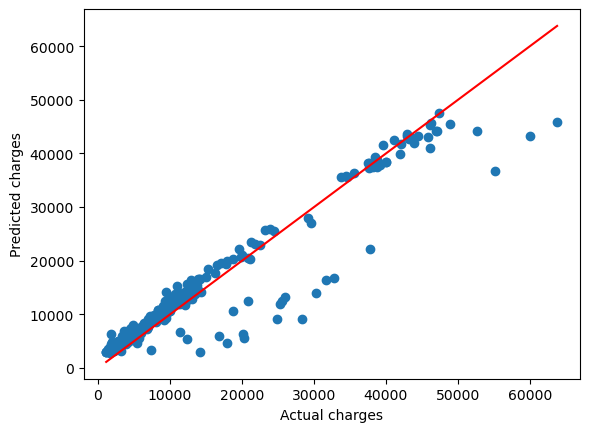

In [119]:
plt.scatter(y_test, pred)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
plt.xlabel("Actual charges")
plt.ylabel("Predicted charges")
plt.show()

**Predicted vs actual charges (test set)**
Most points sit close to the red line, so the model predicts well for bills up to about 50,000, where most of the data is. The errors are mostly one-sided: the model underpredicts. The most expensive patients (actual bills of about 52,000 to 64,000) are predicted at only about 37,000 to 46,000, so predictions seem to level off near 45,000. A second group of about 15 patients, with actual bills of about 12,000 to 38,000, is predicted at about 3,000 to 22,000, far below the line. These are high bills that the six features do not explain. Very few points lie above the line, so the model rarely overestimates.

In [120]:
check = x_test.copy()
check["actual"] = y_test
check["predicted"] = pred.round(0)
check["error"] = (check["actual"] - check["predicted"]).round(0)
check.sort_values("error", ascending=False).head(10)

,age,bmi,children,sex,smoker,region,actual,predicted,error
986,45,27.645,1,female,no,northwest,28340.18885,9174.0,19166.0
818,33,35.530,0,female,yes,northwest,55135.40209,36807.0,18328.0
543,54,47.410,0,female,yes,southeast,63770.42801,45869.0,17901.0
1229,52,34.485,3,male,yes,northwest,60021.39897,43339.0,16682.0
115,60,28.595,0,male,no,northeast,30259.99556,13989.0,16271.0
128,32,17.765,2,female,yes,northwest,32734.18630,16768.0,15966.0
636,35,38.095,2,female,no,northeast,24915.04626,9202.0,15713.0
1302,43,27.800,0,male,yes,southwest,37829.72420,22222.0,15608.0
573,62,36.860,1,female,no,northeast,31620.00106,16486.0,15134.0
291,29,29.640,1,male,no,northeast,20277.80751,5654.0,14624.0


**Largest prediction errors (test set)**
All ten largest errors are underpredictions. Five are smokers (actual bills 32,700 to 63,800, predicted 16,800 to 45,900) and five are non-smokers (actual bills 20,300 to 31,600, predicted 5,700 to 16,500). The non-smoker cases have unusually high bills that age, BMI and the other features cannot explain, probably something outside this dataset such as a serious medical condition.

In [121]:
print(pd.Series(final_model.feature_importances_, index=x_train_enc.columns).round(3).sort_values(ascending=False))

smoker_yes          0.695
bmi                 0.174
age                 0.120
children            0.011
region_southwest    0.001
sex_male            0.000
region_northwest    0.000
region_southeast    0.000
dtype: float64


**Feature importance (final model)**
Smoker status is by far the most important feature (0.695), followed by BMI (0.174) and age (0.120). Children contribute very little (0.011), and sex and region are essentially unused. This agrees with the EDA, where smoking separated charges most clearly and sex, region and children showed little effect on their own.

## Conclusion

**Final model:** tuned Gradient Boosting Regressor (learning rate 0.05, max depth 2, 200 trees), predicting insurance charges from age, sex, BMI, children, smoker status and region.

**How it was chosen:** four models were compared with 5-fold cross-validation on the training set (1,069 rows), using R², MAE and RMSE. Linear Regression was clearly the weakest (R² 0.726, MAE 4,207) because it cannot represent the smoker and BMI interaction seen in the EDA. Random Forest overfitted (training R² 0.974 against cross-validation R² 0.820). Gradient Boosting, Decision Tree and Random Forest were close, so the top two were tuned. Tuned Gradient Boosting was best on all three metrics (R² 0.843, MAE 2,613, RMSE 4,625), but only narrowly over the tuned Decision Tree (R² 0.834, MAE 2,705, RMSE 4,760), and the difference was smaller than the fold-to-fold variation. Selection was therefore based on the lowest cross-validated error with the highest R²; the Decision Tree is a simpler alternative with almost the same performance.

**Test result:** the test set (268 rows) was used once, after the model and settings were fixed. It gave R² 0.899, MAE 2,523 and RMSE 4,299, close to the cross-validation results, so there is no sign of overfitting. The test set is small, so the cross-validation estimate (R² about 0.84, average error about 2,600) is the more cautious figure to quote.

**What drives predictions:** smoker status (importance 0.695), BMI (0.174) and age (0.120) account for about 99% of the model's importance. Sex, region and children contribute almost nothing, which agrees with the EDA.

**Limitations**
- The model underpredicts the most expensive patients: bills above about 50,000 are predicted at about 37,000 to 46,000, and a small group of mid-range bills is predicted far too low. These cases are rare, and the available features cannot explain them.
- The dataset is small (1,337 rows after removing one duplicate), and it has no medical history or other health information.
- Outliers were kept, not removed or capped, because they are genuine high-cost cases (97% are smokers).
- Model performance was not checked separately for subgroups such as smokers and non-smokers, and there was no external validation.

**Future work**
- Test interaction features (for example smoker combined with BMI above 30) and a log transform of the target.
- Check errors separately for smokers and non-smokers.
- Add more data and health-related features, and test other models such as XGBoost.
- Report prediction ranges, not just single values, so users can see the uncertainty.
- Deploy a small Streamlit app, like your churn project.

## 